In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import pickle as p

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, fbeta_score, make_scorer, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TunedThresholdClassifierCV

In [16]:
dataset = pd.read_csv('../data/heart_failure/heart_failure_clinical_records_dataset.csv')
dataset.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [17]:
dataset.columns

Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='str')

In [18]:
features = dataset.drop('DEATH_EVENT', axis=1)
targets = dataset['DEATH_EVENT']

features_trainval, features_test, targets_trainval, targets_test = \
    train_test_split(features, targets, test_size=0.2, stratify=targets)

In [19]:
features_normalized_trainval = (features_trainval - features_trainval.mean())/features_trainval.std()
features_normalized_test = (features_test - features_trainval.mean())/features_trainval.std()

In [20]:
features_normalized_test.iloc[0]


age                        -0.889623
anaemia                     1.186686
creatinine_phosphokinase   -0.437489
diabetes                   -0.868438
ejection_fraction          -0.033277
high_blood_pressure         1.380805
platelets                   0.184160
serum_creatinine           -0.277622
serum_sodium                0.094556
sex                         0.768668
smoking                    -0.701202
time                       -1.560983
Name: 13, dtype: float64

In [21]:
def test(model):
    predictions_train = model.predict(features_normalized_trainval)
    predictions_test = model.predict(features_normalized_test)
    precision_train = precision_score(targets_trainval, predictions_train)
    recall_train = recall_score(targets_trainval, predictions_train)
    precision_test = precision_score(targets_test, predictions_test)
    recall_test = recall_score(targets_test, predictions_test)
    print(f'Train Precision: {precision_train:.3f} Recall: {recall_train:.3f}')
    print(f'Test Precision: {precision_test:.3f} Recall: {recall_test:.3f}')

Train Precision: 0.792 Recall: 0.494
Test Precision: 0.650 Recall: 0.684


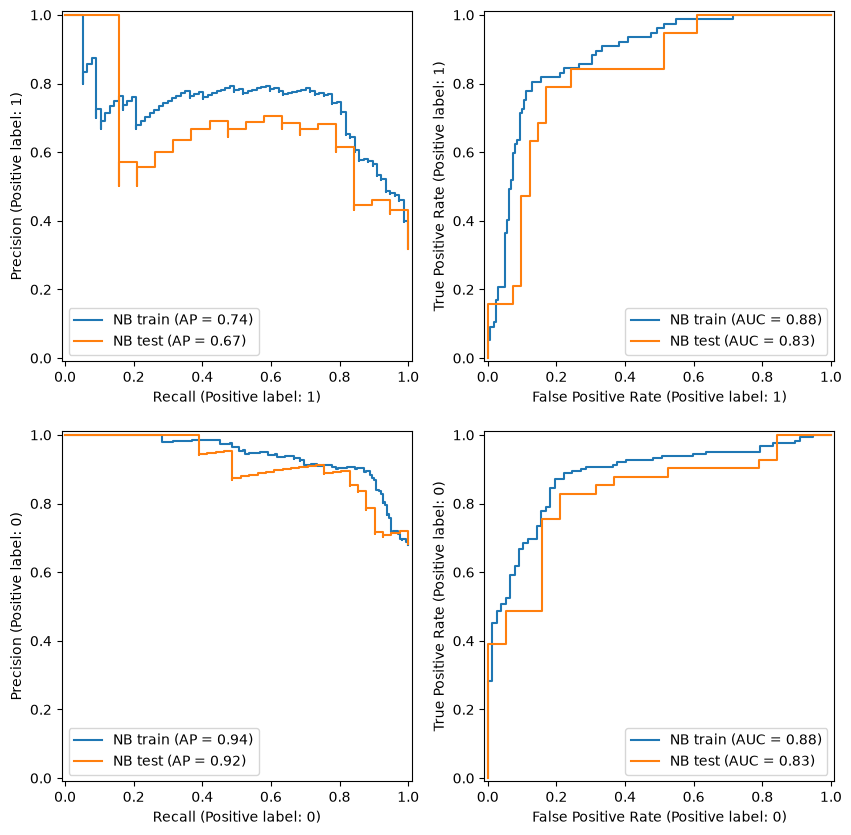

In [34]:
nb1 = GaussianNB()
nb1.fit(features_normalized_trainval, targets_trainval)
test(nb1)
fig, ax = plt.subplots(2, 2, figsize=(10,10))
PrecisionRecallDisplay.from_estimator(nb1, features_normalized_trainval, targets_trainval, ax=ax[0,0], name='NB train')
PrecisionRecallDisplay.from_estimator(nb1, features_normalized_test, targets_test, ax=ax[0,0], name='NB test')
RocCurveDisplay.from_estimator(nb1, features_normalized_trainval, targets_trainval, ax=ax[0,1], name='NB train')
RocCurveDisplay.from_estimator(nb1, features_normalized_test, targets_test, ax=ax[0,1], name='NB test')
PrecisionRecallDisplay.from_estimator(nb1, features_normalized_trainval, targets_trainval, pos_label=0, ax=ax[1,0], name='NB train')
PrecisionRecallDisplay.from_estimator(nb1, features_normalized_test, targets_test, pos_label=0, ax=ax[1,0], name='NB test')
RocCurveDisplay.from_estimator(nb1, features_normalized_trainval, targets_trainval, pos_label=0, ax=ax[1,1], name='NB train')
RocCurveDisplay.from_estimator(nb1, features_normalized_test, targets_test, pos_label=0, ax=ax[1,1], name='NB test')

Train Precision: 1.000 Recall: 1.000
Test Precision: 0.682 Recall: 0.789


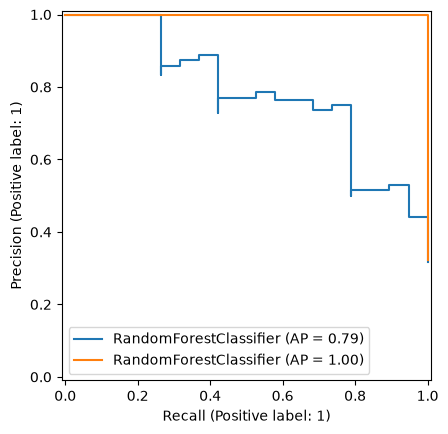

In [23]:
rf1 = RandomForestClassifier()
rf1.fit(features_normalized_trainval, targets_trainval)
test(rf1)
fig, ax = plt.subplots(1,1)
PrecisionRecallDisplay.from_estimator(rf1, features_normalized_test, targets_test, ax=ax)
PrecisionRecallDisplay.from_estimator(rf1, features_normalized_trainval,targets_trainval, ax=ax)

In [24]:
predictions =  rf1.predict_proba(features_normalized_trainval)
unique_probs = np.unique(predictions[:,1])
for threshold in unique_probs:
    predictions_ = (predictions[:,1]>=threshold)*1
    precision = precision_score(targets_trainval, predictions_)
    recall = recall_score(targets_trainval, predictions_)
    print(f'Threshold: {threshold} precision {precision} recall {recall}')

Threshold: 0.0 precision 0.32217573221757323 recall 1.0
Threshold: 0.01 precision 0.34841628959276016 recall 1.0
Threshold: 0.02 precision 0.4031413612565445 recall 1.0
Threshold: 0.03 precision 0.45294117647058824 recall 1.0
Threshold: 0.04 precision 0.48427672955974843 recall 1.0
Threshold: 0.05 precision 0.5347222222222222 recall 1.0
Threshold: 0.06 precision 0.5703703703703704 recall 1.0
Threshold: 0.07 precision 0.5923076923076923 recall 1.0
Threshold: 0.08 precision 0.6363636363636364 recall 1.0
Threshold: 0.09 precision 0.652542372881356 recall 1.0
Threshold: 0.1 precision 0.6695652173913044 recall 1.0
Threshold: 0.11 precision 0.6754385964912281 recall 1.0
Threshold: 0.12 precision 0.6875 recall 1.0
Threshold: 0.13 precision 0.7 recall 1.0
Threshold: 0.14 precision 0.719626168224299 recall 1.0
Threshold: 0.15 precision 0.7264150943396226 recall 1.0
Threshold: 0.16 precision 0.7403846153846154 recall 1.0
Threshold: 0.17 precision 0.7857142857142857 recall 1.0
Threshold: 0.18 pre

In [25]:
class ThresholdClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator, threshold=0.5):
        self.estimator = estimator
        self.threshold = threshold

    def fit(self, x, y):
        if hasattr(self.estimator, 'classes_'):
            self.classes_ = self.estimator.classes_
            return self
        self.estimator.fit(x,y)
        return self

    def predict(self, x):
        probabilities = self.predict_proba(x)
        return (probabilities[:,1]>=self.threshold).astype(int)

    def predict_proba(self, x):
        return self.estimator.predict_proba(x)
        

In [26]:
rft1 = ThresholdClassifier(rf1, threshold=0.62)
test(rft1)

Train Precision: 1.000 Recall: 1.000
Test Precision: 0.750 Recall: 0.789


In [66]:
rf_tuned = TunedThresholdClassifierCV(RandomForestClassifier(), cv=5, scoring=make_scorer(fbeta_score, beta=0.99))
rf_tuned.fit(features_normalized_trainval, targets_trainval)
test(rf_tuned)

Train Precision: 1.000 Recall: 1.000
Test Precision: 0.531 Recall: 0.895


In [27]:
with (open('rf1.pickle', 'wb') as f):
    p.dump(rf1, f)

<BarContainer object of 12 artists>

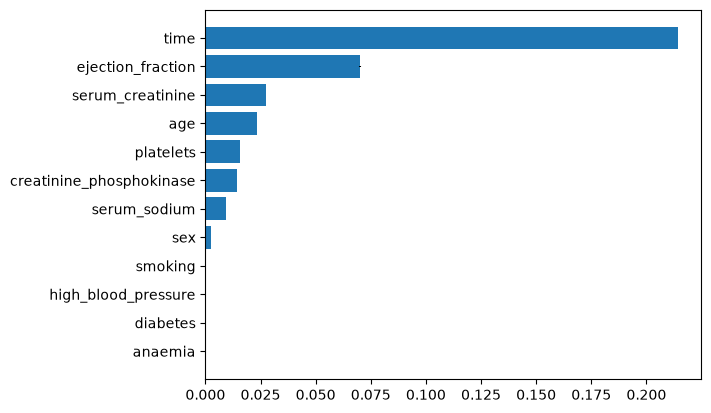

In [58]:
results = permutation_importance(rf1, features_normalized_trainval, targets_trainval)
# Plot precounted data using pyplot
results_frame = pd.DataFrame({'feature': features.columns, 'mean':results.importances_mean, 'std':results.importances_std})
results_frame = results_frame.sort_values('mean')
plt.barh(results_frame['feature'], results_frame['mean'], yerr=results_frame['std'])


<Axes: xlabel='importance', ylabel='feature'>

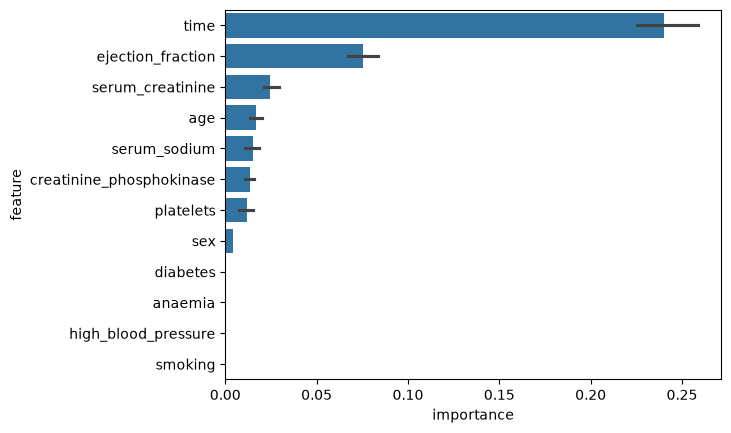

In [56]:
# Plot raw data using seaborn
results_frame_raw = pd.DataFrame({column: results.importances[i] for i, column in enumerate(features.columns)})
results_frame_raw = results_frame_raw.melt(value_vars=results_frame_raw.columns, var_name='feature', value_name='importance')
# order not working because of indexing
order = results_frame_raw.groupby('feature')['importance'].mean().sort_values(ascending=False).index
sb.barplot(data=results_frame_raw, x='importance', y='feature', order=order)